# Peak picking QC

In [1]:
import nescafe23 as n23
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmps
from matplotlib.patches import Rectangle

%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

## Lower Array

In [2]:
dss = n23.open_receptions()
peak_locations = n23.open_peak_locations()

100%|██████████| 23/23 [00:16<00:00,  1.37it/s]


In [139]:
Tx_idx = 22
ds_lower = dss[Tx_idx].swap_dims({'hydrophone':'nominal_depth'}).rename({'nominal_depth':'depth'})[32:,:].sel({'time':slice(98, 115)})

In [140]:
thetas = np.linspace(-35,35,200)
bf_lower = n23.ULA_conventional_beamform(ds_lower, thetas)

In [141]:
%matplotlib widget

In [ ]:
peak_boxes = n23.processing.PEAK_BOXES_LOWER.copy()
plt.close()
fig, axes = plt.subplots(3,1,figsize=(13, 18))

axes = axes.flatten()
xlims = [[100,104], [104,108], [108,112]]
for pane in range(3):
    ax = axes[pane]
    plt.sca(ax)

    (20*np.log10(np.abs(bf_lower))).plot(x='time', cmap=cmps.timefront(), rasterized=True, vmin=110, ax=ax)

    artists = []  # list of (t1, t2, th1, th2, patch, text)
    for peak, box in peak_boxes.items():
        if isinstance(box, tuple):
            t1, t2, th1, th2 = box
        elif isinstance(box, dict):
            t1, t2, th1, th2 = box[Tx_idx]
        else:
            continue
        rect = Rectangle((t1, th1), t2 - t1, th2 - th1, linewidth=1, edgecolor='k', facecolor='none')
        ax.add_patch(rect)

        plt.scatter(peak_locations['times'][peak][Tx_idx], peak_locations['angles'][peak][Tx_idx], lw=1, edgecolor='k', facecolors=(1,1,1,0.3))
        box_properties = dict(
            facecolor='white',  # Background color
            edgecolor='white',    # Border color
            alpha=0.5            # Transparency (0 to 1)
        )
        txt = ax.text(t1, th2, f"{peak}\n{peak_locations['snrs'][peak][Tx_idx]:0.2f}", color='k', fontsize=8, va='bottom', bbox=box_properties)
        artists.append((t1, t2, th1, th2, rect, txt))
    def update_visibility(ax):
        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()
        for t1, t2, th1, th2, rect, txt in artists:
            visible = t1 < x1 and t2 > x0 and th1 < y1 and th2 > y0
            rect.set_visible(visible)
            txt.set_visible(visible)
        fig.canvas.draw_idle()

    ax.callbacks.connect('xlim_changed', update_visibility)
    ax.callbacks.connect('ylim_changed', update_visibility)
    update_visibility(ax)

    plt.title(f'Transmission {Tx_idx}')
    plt.xlim(xlims[pane])

## Upper Array

In [2]:
dss = n23.open_receptions()

  0%|          | 0/23 [00:00<?, ?it/s]

100%|██████████| 23/23 [00:16<00:00,  1.36it/s]


In [3]:
peak_locations = n23.open_peak_locations()


In [4]:
import fsspec
from scipy import io

fs = fsspec.filesystem('')
fn_base = '/mnt/oadl-storage/PersonalStorage/Colosi/Localization/NESCAFE2023/picks/'
fns = fs.glob(f'{fn_base}beampeaksupper*.mat')

colosi_peak_locations = []
for fn in fns:
    colosi_peak_locations.append(io.loadmat(fn))


In [11]:
T_t = n23.data.open_T_t()['dT_t']

In [27]:
Tx_idx = 15
ds_upper = dss[Tx_idx].swap_dims({'hydrophone':'nominal_depth'}).rename({'nominal_depth':'depth'})[:32,:].sel({'time':slice(98, 115)})

In [28]:
thetas = np.linspace(-35,35,200)
bf_upper = n23.ULA_conventional_beamform(ds_upper, thetas)

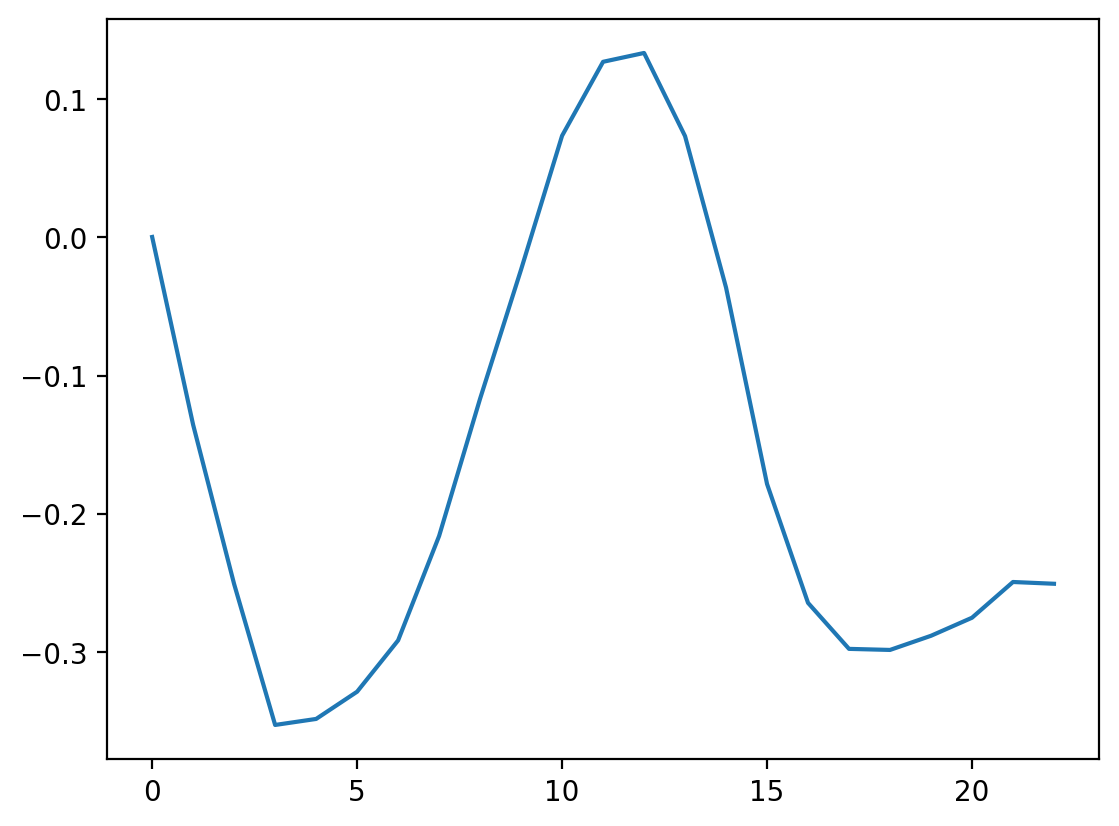

In [30]:
plt.plot(T_t)

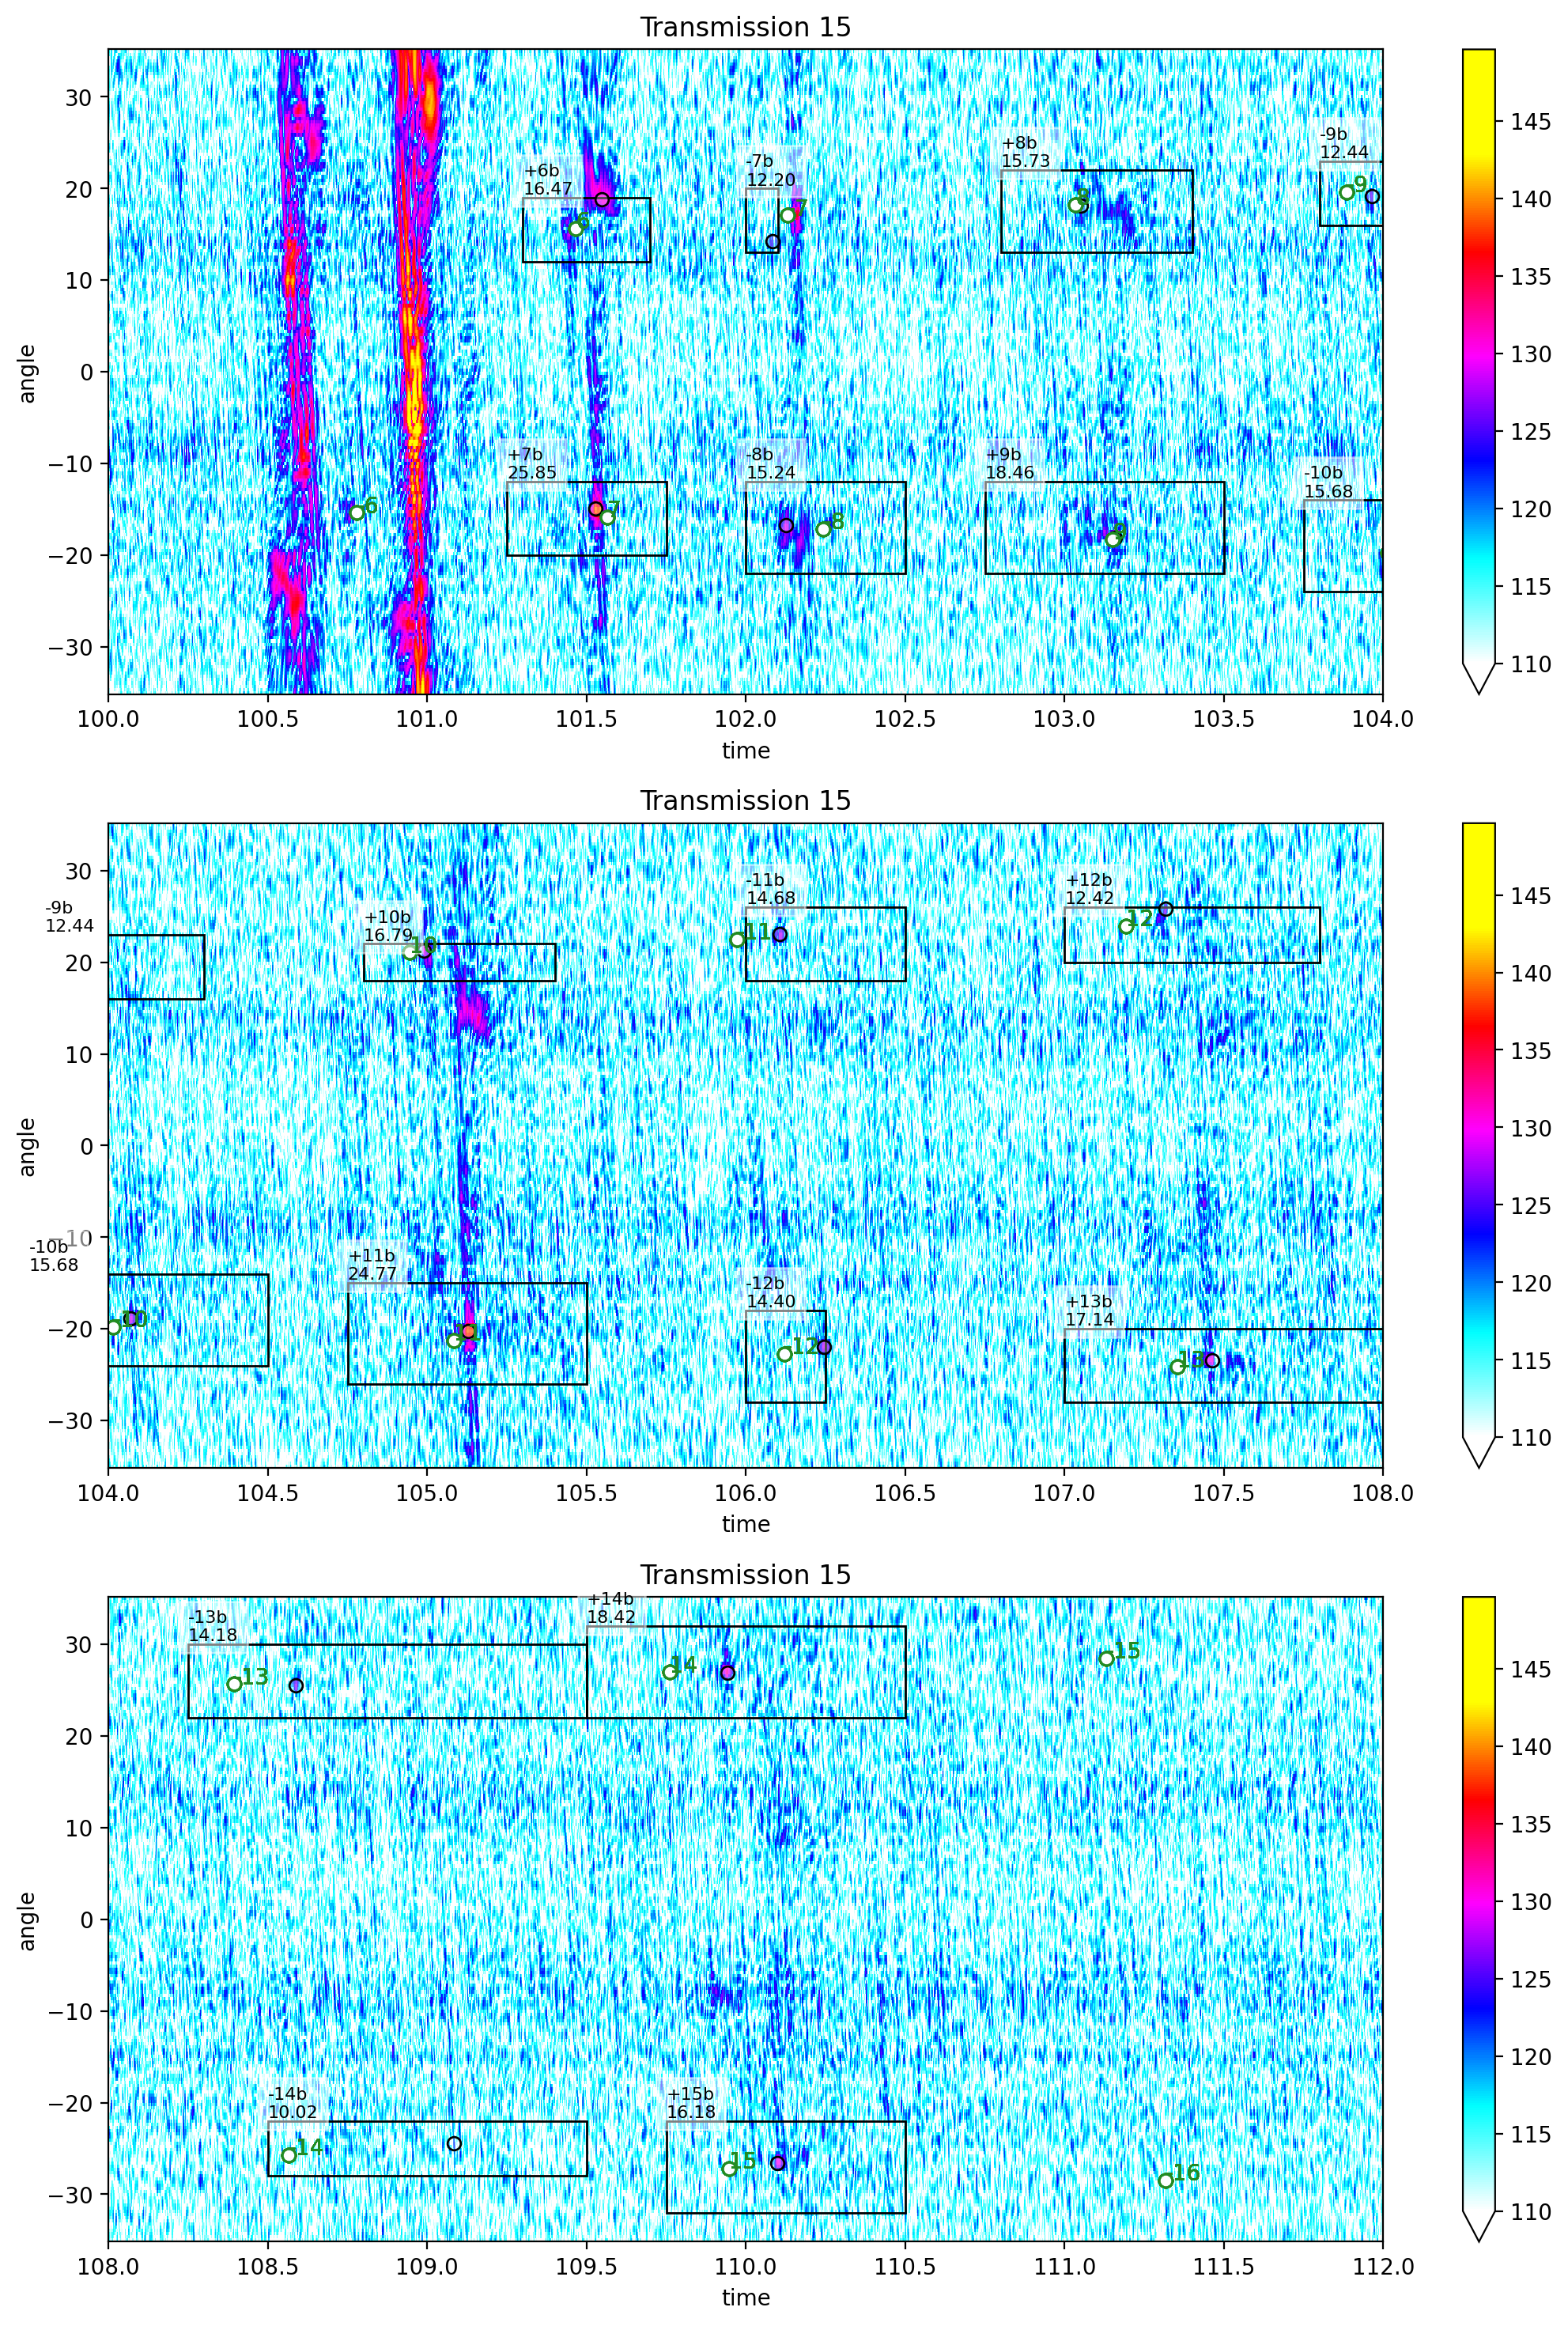

In [31]:
peak_boxes = n23.processing.PEAK_BOXES_UPPER.copy()
plt.close()
fig, axes = plt.subplots(3,1,figsize=(13, 18))

axes = axes.flatten()
xlims = [[100,104], [104,108], [108,112]]
for pane in range(3):
    ax = axes[pane]
    plt.sca(ax)

    (20*np.log10(np.abs(bf_upper))).plot(x='time', cmap=cmps.timefront(), rasterized=True, vmin=110, ax=ax)

    artists = []  # list of (t1, t2, th1, th2, patch, text)
    for peak, box in peak_boxes.items():
        if isinstance(box, tuple):
            t1, t2, th1, th2 = box
        elif isinstance(box, dict):
            t1, t2, th1, th2 = box[Tx_idx]
        else:
            continue
        rect = Rectangle((t1, th1), t2 - t1, th2 - th1, linewidth=1, edgecolor='k', facecolor='none')
        ax.add_patch(rect)


        # JR's picked peaks
        plt.scatter(peak_locations['upper_times'][peak][Tx_idx], peak_locations['upper_angles'][peak][Tx_idx], lw=1, edgecolor='k', facecolors=(1,1,1,0.3))
        
        # JC's picked peaks
        plt.scatter(colosi_peak_locations[Tx_idx]['eig_time'] + T_t[Tx_idx], colosi_peak_locations[Tx_idx]['eig_ang'], lw=1, edgecolor='#228B22', facecolors=(1,1,1,0.3))
        
        # add JC ray IDs
        for i in range(len(colosi_peak_locations[0]['eig_id'][0])):
            t_id = colosi_peak_locations[Tx_idx]['eig_time'][0,i] + T_t[Tx_idx]
            if xlims[pane][0] <= t_id <= xlims[pane][1]:
                plt.text(t_id, colosi_peak_locations[Tx_idx]['eig_ang'][0,i], colosi_peak_locations[Tx_idx]['eig_id'][0,i], color='#228B22')
        box_properties = dict(
            facecolor='white',  # Background color
            edgecolor='white',    # Border color
            alpha=0.5            # Transparency (0 to 1)
        )
        txt = ax.text(t1, th2, f"{peak}\n{peak_locations['upper_snrs'][peak][Tx_idx]:0.2f}", color='k', fontsize=8, va='bottom', bbox=box_properties)
        artists.append((t1, t2, th1, th2, rect, txt))
    def update_visibility(ax):
        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()
        for t1, t2, th1, th2, rect, txt in artists:
            visible = t1 < x1 and t2 > x0 and th1 < y1 and th2 > y0
            rect.set_visible(visible)
            txt.set_visible(visible)
        fig.canvas.draw_idle()

    ax.callbacks.connect('xlim_changed', update_visibility)
    ax.callbacks.connect('ylim_changed', update_visibility)
    update_visibility(ax)

    plt.title(f'Transmission {Tx_idx}')
    plt.xlim(xlims[pane])